# Extracting bridge vibration from the acceleration measured in a car with a CNN

**Objective:** evaluate whether a convolutional neural network can recover the vibration of a bridge from the acceleration recorded by a phone inside a car crossing it.

## 1. Physical setup

### 1.1 System

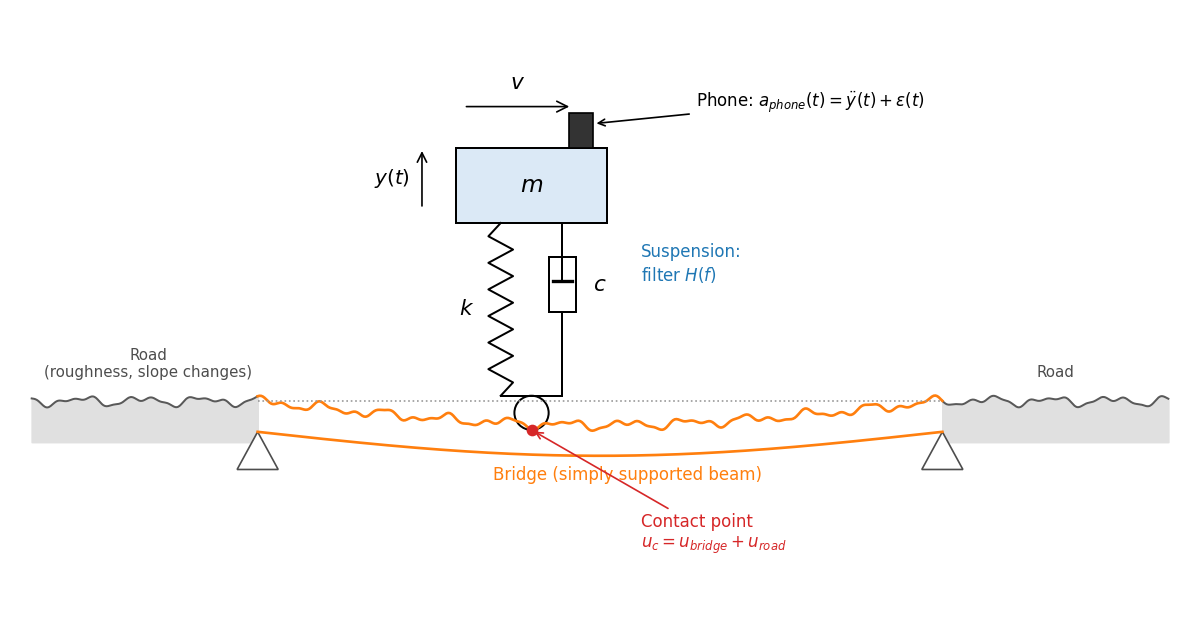

Simplified single-degree-of-freedom car (mass $m$, spring $k$, damper $c$) crossing a simply supported bridge at constant speed $v$, with a rough road before, on and after the bridge.

### 1.2 Contact point

The wheel follows the surface it travels over. The vertical motion under the wheel is the sum of the bridge and the road:

$$u_c(t) = u_{\text{bridge}}\big(x(t), t\big) + u_{\text{road}}\big(x(t)\big), \qquad x(t) = v\,t$$

- $u_c(t)$: vertical displacement of the contact point.
- $u_{\text{bridge}}$: deflection of the bridge at the wheel position.
- $u_{\text{road}}$: road profile at that position (roughness and slope changes).
- $x(t)$: wheel position.

### 1.3 The car as a filter

The contact point excites the car from below:

$$m\,\ddot y + c\,(\dot y - \dot u_c) + k\,(y - u_c) = 0$$

- $y(t)$: vertical displacement of the car body, where the phone is.

### 1.4 Measured signal

Combining the above, the acceleration recorded by the phone is:

$$a_{\text{phone}}(t) = \ddot y(t) + \varepsilon(t)$$

- $\varepsilon(t)$: sensor noise.

## 2. Problem

Recovering $\ddot u_{\text{bridge}}(t)$ from $a_{\text{phone}}(t)$ involves two steps:

1. **Undo the dynamic effect of the car:** go from $a_{\text{phone}}$ to $\ddot u_c$. This requires knowing $m$, $c$ and $k$ (Yang et al., 2019), which are unknown for an arbitrary car.
2. **Separate the bridge from the road:** within $\ddot u_c$, isolate $\ddot u_{\text{bridge}}$ from $\ddot u_{\text{road}}$.

## 3. Proposal

A CNN that solves both steps at once, without knowing $m$, $c$ or $k$, by learning from many simulated cars and bridges:

$$\hat{\ddot u}_{\text{bridge}}(t) = f_\theta\big(a_{\text{phone}}(t)\big)$$

| | Content |
|---|---|
| Input | $a_{\text{phone}}(t)$: acceleration measured by the phone |
| Output | $\ddot u_{\text{bridge}}(t)$: bridge acceleration under the wheel |
| Model $f_\theta$ | Convolutional Neural Network (CNN) |

Target at the contact point: it contains the bridge frequencies and not the car frequency (Yang et al., 2019).

Additional option: since the biggest challenge for the CNN is learning the dynamic effect of the car without knowing its properties, the segment before the bridge could be included as an input, as context to "calibrate" the car.

### 3.1 General idea of a 1D CNN

A kernel (a short segment of weights) slides along the signal over time and responds more strongly where it finds the pattern it learned. In the illustrative example, a kernel shaped like the bridge oscillation highlights the segment in which the car is on the bridge (2–8 s):

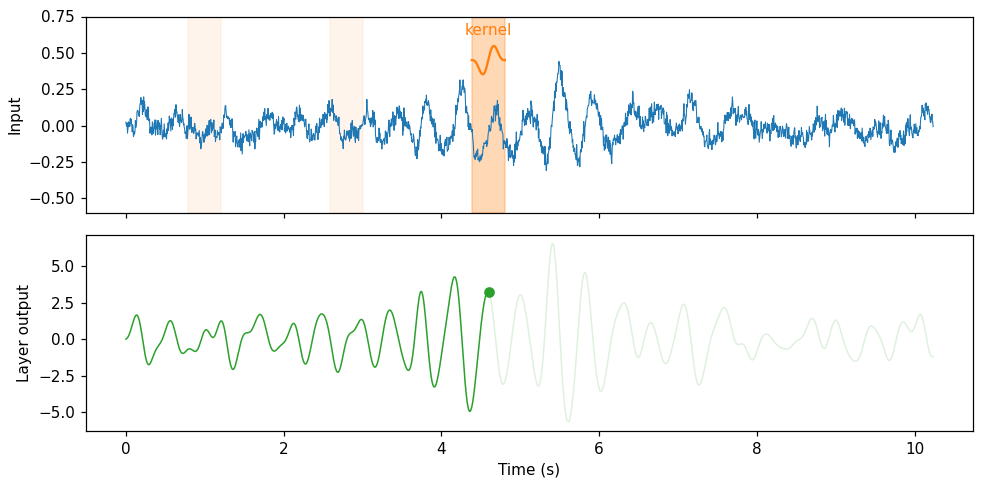

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# ---------- Synthetic phone signal (illustration only) ----------
fs = 200.0
t = np.arange(0, 10.24, 1 / fs)
rng = np.random.default_rng(0)
on_bridge = (t > 2.0) & (t < 8.0)
bridge = 0.15 * np.sin(2 * np.pi * 2.4 * t) * np.sin(np.pi * (t - 2.0) / 6.0) * on_bridge
road = np.convolve(rng.normal(0, 1, t.size), np.ones(25) / 25, mode="same") * 0.3
car = 0.05 * np.sin(2 * np.pi * 1.7 * t + 0.5)
signal = bridge + road + car + rng.normal(0, 0.03, t.size)

def cross_corr(x, kern):
    """Cross-correlation as used in CNN layers ('same' padding)."""
    return np.correlate(x, kern, mode="same")

# ---------- One kernel sliding along the signal ----------
kern_osc = np.sin(2 * np.pi * 2.4 * np.arange(-42, 43) / fs) * np.hanning(85)   # oscillation pattern
out = cross_corr(signal, kern_osc)
t_now = 4.6                                                                      # current kernel position
i_now = int(t_now * fs)
half = len(kern_osc) // 2

fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
ax[0].plot(t, signal, lw=0.7, color="tab:blue")
for tc, alpha in [(1.0, 0.08), (2.8, 0.08), (t_now, 0.3)]:
    ax[0].axvspan(tc - half / fs, tc + half / fs, color="tab:orange", alpha=alpha)
ax[0].plot(t[i_now - half:i_now + half + 1], kern_osc * 0.15 + 0.45, color="tab:orange", lw=1.5)
ax[0].text(t_now, 0.62, "kernel", ha="center", color="tab:orange")
ax[0].set_ylabel("Input"); ax[0].set_ylim(-0.6, 0.75)
ax[1].plot(t[:i_now + 1], out[:i_now + 1], color="tab:green", lw=1)
ax[1].plot(t[i_now:], out[i_now:], color="tab:green", lw=1, alpha=0.15)
ax[1].plot(t_now, out[i_now], "o", color="tab:green")
ax[1].set_ylabel("Layer output"); ax[1].set_xlabel("Time (s)")
fig.tight_layout()
plt.show()

A layer has several kernels, each one attentive to a different pattern, and by stacking layers the network combines those patterns into more complex ones until it reconstructs the bridge vibration.

## 4. Data

Signals simulated with a vehicle-bridge simulator, in a simplified version:

| Element | Simplification |
|---|---|
| Bridge | Simply supported beam, spans from 15 to 60 m |
| Car | Single degree of freedom, natural frequency from 1 to 3 Hz (the same range used in Talebi-Kalaleh and Mei, 2026) * |
| Interaction | Decoupled: car as a moving load, valid if the car mass ≪ the bridge mass (Yang et al., 2019; Talebi-Kalaleh and Mei, 2026) |
| Road | ISO 8608 roughness (Agostinacchio et al., 2014; Talebi-Kalaleh and Mei, 2026) |
| Phone | White noise, 200 Hz |
| Excluded | Engine, pitching, phone mount |

Between 2,000 and 5,000 signals, each with a different bridge, car and speed. Example of one crossing:

*Note: sources supporting that car frequencies fall in this range are still to be confirmed.

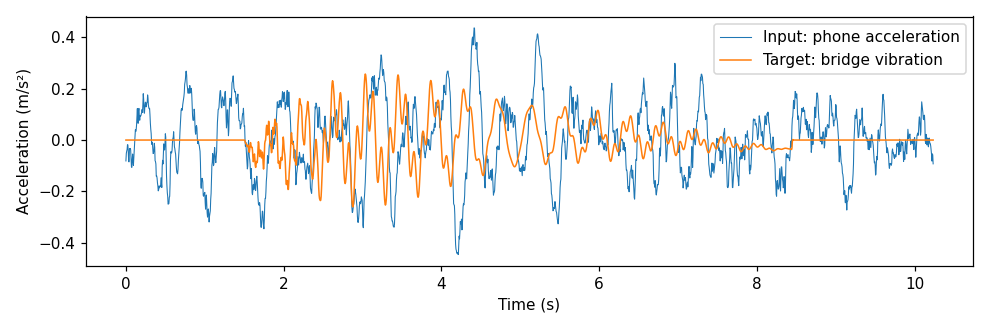

In [3]:
import vehicle_bridge_signal as vbs

# One simulated crossing (simplified car and bridge)
cfg = vbs.load_preset("snr_controlled_dataset", {"vehicle.model": "sprung_mass",
                                                 "simulation.interaction": "decoupled",
                                                 "engine.enabled": False})
scenario, seed = vbs.sample_scenario(cfg, seed=7)
res = vbs.simulate(scenario, seed)

a_tel = res.measured                                                              # model input
a_bridge = sum(res.contact[k][0] for k in res.contact if k.startswith("bridge"))  # model target

plt.figure(figsize=(9, 3))
plt.plot(res.t, a_tel, lw=0.7, label="Input: phone acceleration")
plt.plot(res.t, a_bridge, lw=1.0, label="Target: bridge vibration")
plt.xlabel("Time (s)"); plt.ylabel("Acceleration (m/s²)"); plt.legend()
plt.show()